In [2]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("tawfikelmetwally/employee-dataset")

print("Path to dataset files:", path)

100%|██████████| 18.5k/18.5k [00:00<00:00, 11.0MB/s]

Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/tawfikelmetwally/employee-dataset/versions/1


In [3]:
import os
print(os.listdir(path))

['Employee.csv']


In [4]:
import pandas as pd
df= pd.read_csv(os.path.join(path,"Employee.csv"))

In [9]:
#understand the data

print(df.head())
print(df.tail())
print(df.sample(10))
print(df.info())

   Education  JoiningYear       City  PaymentTier  Age  Gender EverBenched  \
0  Bachelors         2017  Bangalore            3   34    Male          No   
1  Bachelors         2013       Pune            1   28  Female          No   
2  Bachelors         2014  New Delhi            3   38  Female          No   
3    Masters         2016  Bangalore            3   27    Male          No   
4    Masters         2017       Pune            3   24    Male         Yes   

   ExperienceInCurrentDomain  LeaveOrNot  
0                          0           0  
1                          3           1  
2                          2           0  
3                          5           1  
4                          2           1  
      Education  JoiningYear       City  PaymentTier  Age  Gender EverBenched  \
4648  Bachelors         2013  Bangalore            3   26  Female          No   
4649    Masters         2013       Pune            2   37    Male          No   
4650    Masters         2018  

In [12]:
print(df.shape)
print(df.shape[0])
print(df.shape[1])

(4653, 9)
4653
9


In [17]:
# print(df.isnull().sum())
# print(df.isnull().sum().sum())
# print("total duplicate value in dataset ", df.duplicated().sum())
#df[df.duplicated()]

,Education,JoiningYear,City,PaymentTier,Age,Gender,EverBenched,ExperienceInCurrentDomain,LeaveOrNot
111,Bachelors,2017,Pune,2,27,Female,No,5,1
130,Bachelors,2017,Bangalore,3,26,Female,No,4,0
138,Bachelors,2017,New Delhi,3,28,Male,No,2,0
160,Bachelors,2014,Bangalore,3,28,Female,No,3,0
167,Bachelors,2014,Bangalore,3,25,Male,No,3,0
...,...,...,...,...,...,...,...,...,...
4640,Bachelors,2015,Bangalore,3,35,Male,No,0,0
4642,Bachelors,2012,Bangalore,3,36,Female,No,4,0
4646,Bachelors,2013,Bangalore,3,25,Female,No,3,0
4648,Bachelors,2013,Bangalore,3,26,Female,No,4,0


In [30]:
# here we are selecting input and output colum
X=df.drop("LeaveOrNot", axis=1)
y=df["LeaveOrNot"]

In [31]:
#split and train the data
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test=train_test_split(
    X,
    y,
    test_size=.2,
    random_state=42
)

In [32]:
categorical_feature=X_train.select_dtypes(
    include=["object"]
).columns
numerical_feature=X_train.select_dtypes(
    include=["int64"]
).columns

In [33]:

#Apply OneHotEncoding
from sklearn.preprocessing import OneHotEncoder
encode=OneHotEncoder(
    handle_unknown="ignore"
)






In [35]:
X_train_encoded=encode.fit_transform(
    X_train[categorical_feature]
)

X_test_encoded = encode.transform(
    X_test[categorical_feature]
)


In [40]:
#combine categorical and numerical data both
import pandas as pd
X_train_final=pd.concat([
    pd.DataFrame(
        X_train_encoded.toarray(),
        columns=encode.get_feature_names_out(categorical_feature),
        index=X_train.index
    ),
     X_train[numerical_feature]
],axis=1)


#test data
X_test_final=pd.concat([
    pd.DataFrame(
        X_test_encoded.toarray(),
        columns=encode.get_feature_names_out(categorical_feature),
        index=X_test.index
    ),
    X_test[numerical_feature]
],axis=1)

In [41]:
print(X_train_final.head())
print(X_train_final.shape)

print(X_test_final.head())
print(X_test_final.shape)

      Education_Bachelors  Education_Masters  Education_PHD  City_Bangalore  \
2850                  0.0                1.0            0.0             0.0   
589                   1.0                0.0            0.0             1.0   
2086                  0.0                1.0            0.0             0.0   
445                   0.0                1.0            0.0             0.0   
3654                  0.0                1.0            0.0             0.0   

      City_New Delhi  City_Pune  Gender_Female  Gender_Male  EverBenched_No  \
2850             1.0        0.0            0.0          1.0             1.0   
589              0.0        0.0            0.0          1.0             1.0   
2086             0.0        1.0            0.0          1.0             1.0   
445              0.0        1.0            0.0          1.0             1.0   
3654             1.0        0.0            0.0          1.0             1.0   

      EverBenched_Yes  JoiningYear  PaymentTier  A

In [45]:
from sklearn.linear_model import LogisticRegression
model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

In [46]:
model.fit(
    X_train_final,
    y_train
)

LogisticRegression(max_iter=1000, random_state=42)

In [47]:
y_pred = model.predict(X_test_final)

In [48]:
print("Actual values:", y_test.values[:10])
print("Predicted values:", y_pred[:10])

Actual values: [1 0 1 0 0 1 1 1 0 1]
Predicted values: [0 0 0 1 0 0 1 1 0 1]


In [49]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy)

Model Accuracy: 0.7443609022556391


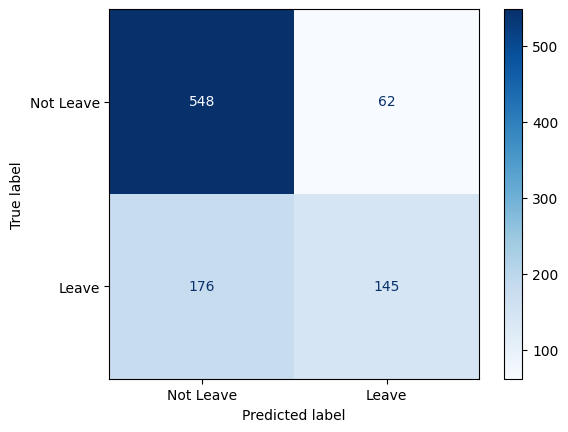

In [50]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Not Leave", "Leave"]
)

disp.plot(cmap="Blues")
plt.show()